In [ ]:
!pip install networkx pandas numpy matplotlib -q

In [ ]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from dataclasses import dataclass
from copy import deepcopy
import random

random.seed(42)
np.random.seed(42)


Define the disaster environment

In [ ]:
# Disaster affected areas

areas = {
    "A1": {
        "name": "Riverside",
        "population": 120,
        "vulnerable": 35,
        "flood": 2.4,
        "road_safety": 0.35,
        "confidence": 0.90
    },

    "A2": {
        "name": "Market Area",
        "population": 90,
        "vulnerable": 20,
        "flood": 1.6,
        "road_safety": 0.55,
        "confidence": 0.65
    },

    "A3": {
        "name": "Central Colony",
        "population": 70,
        "vulnerable": 10,
        "flood": 0.8,
        "road_safety": 0.80,
        "confidence": 0.80
    },

    "A4": {
        "name": "Hill View",
        "population": 110,
        "vulnerable": 40,
        "flood": 2.0,
        "road_safety": 0.40,
        "confidence": 0.55
    }
}

# Rescue teams

rescue_teams = {
    "T1": {
        "location": "BaseA",
        "capacity": 140,
        "speed": 1.0
    },

    "T2": {
        "location": "BaseB",
        "capacity": 100,
        "speed": 1.1
    },

    "T3": {
        "location": "BaseA",
        "capacity": 120,
        "speed": 1.2
    },

    "T4": {
        "location": "BaseB",
        "capacity": 120,
        "speed": 0.9
    }
}

# Emergency shelters

shelters = {
    "S1": {
        "name": "School Shelter",
        "capacity": 150,
        "available": True
    },

    "S2": {
        "name": "Community Hall",
        "capacity": 120,
        "available": True
    },

    "S3": {
        "name": "Relief Camp",
        "capacity": 180,
        "available": True
    }
}

print("Affected Areas:", len(areas))
print("Rescue Teams:", len(rescue_teams))
print("Shelters:", len(shelters))

Affected Areas: 4
Rescue Teams: 4
Shelters: 3


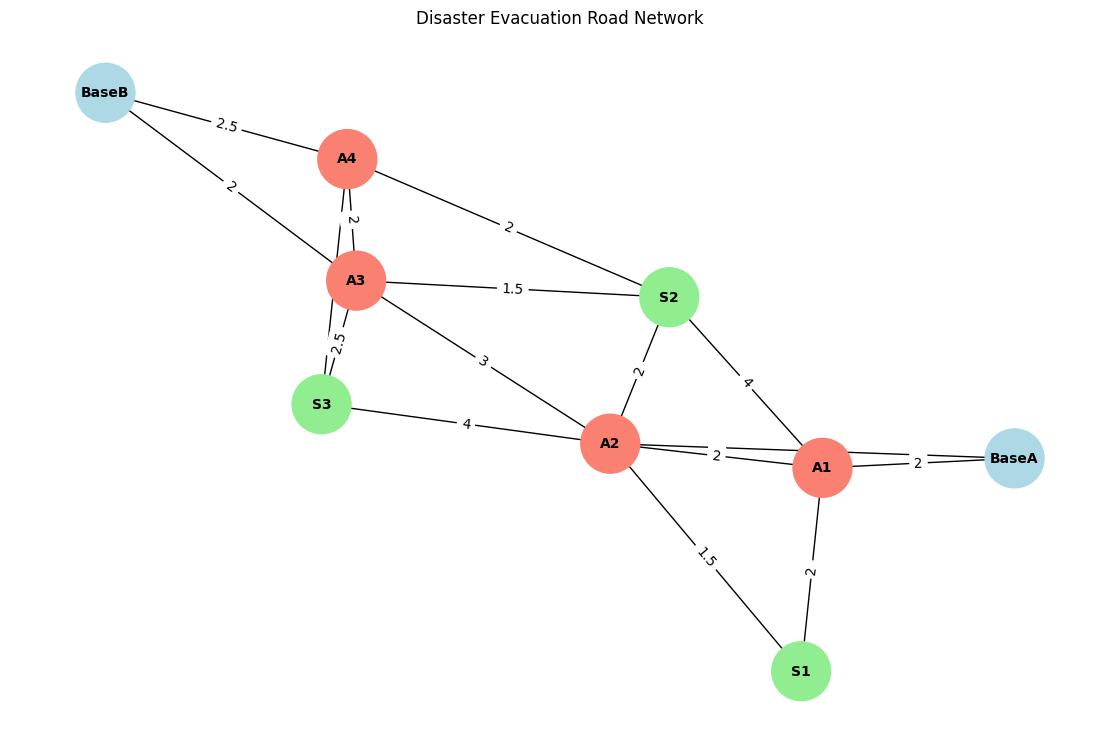

In [ ]:
#Create the road network
G = nx.Graph()

roads = [
    ("BaseA", "A1", 2),
    ("BaseA", "A2", 3),
    ("BaseB", "A3", 2),
    ("BaseB", "A4", 2.5),

    ("A1", "A2", 2),
    ("A2", "A3", 3),
    ("A3", "A4", 2),

    ("A1", "S1", 2),
    ("A2", "S1", 1.5),
    ("A2", "S2", 2),
    ("A3", "S2", 1.5),
    ("A4", "S2", 2),
    ("A4", "S3", 1.5),
    ("A3", "S3", 2.5),
    ("A1", "S2", 4),
    ("A2", "S3", 4)
]

for u, v, distance in roads:
    G.add_edge(
        u,
        v,
        distance=distance,
        weight=distance,
        blocked=False
    )

def draw_city_graph(graph, title="Disaster Evacuation Road Network"):

    pos = nx.spring_layout(graph, seed=42)

    colors = []

    for node in graph.nodes():

        if node.startswith("Base"):
            colors.append("lightblue")

        elif node.startswith("A"):
            colors.append("salmon")

        else:
            colors.append("lightgreen")

    plt.figure(figsize=(11, 7))

    nx.draw(
        graph,
        pos,
        with_labels=True,
        node_color=colors,
        node_size=1800,
        font_weight="bold",
        font_size=10
    )

    labels = nx.get_edge_attributes(graph, "distance")

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=labels
    )

    plt.title(title)
    plt.show()

draw_city_graph(G)

#Exercise 1 – Knowledge Representation
Objective: Represent rescue teams, affected areas, shelters and their relationships using a suitable knowledge representation technique.

In [ ]:
#Build the knowledge graph
knowledge_graph = nx.DiGraph()

facts = []

# Add rescue team relationships

for team, details in rescue_teams.items():

    facts.append(
        (team, "located_at", details["location"])
    )

    knowledge_graph.add_edge(
        team,
        details["location"],
        relation="located_at"
    )

# Add affected area relationships

for area, details in areas.items():

    facts.append(
        (area, "has_population", str(details["population"]))
    )

    facts.append(
        (area, "affected_by", "Flood")
    )

    knowledge_graph.add_edge(
        area,
        "Flood",
        relation="affected_by"
    )

# Add shelter relationships

for shelter, details in shelters.items():

    facts.append(
        (shelter, "has_capacity", str(details["capacity"]))
    )

    facts.append(
        (shelter, "is_shelter", "True")
    )

# Add road relationships

for u, v, data in G.edges(data=True):

    facts.append(
        (u, "connected_to", v)
    )

    knowledge_graph.add_edge(
        u,
        v,
        relation="connected_to"
    )

# Display knowledge base

print("KNOWLEDGE BASE\n")

for fact in facts:
    print(fact)

print("\nTotal facts:", len(facts))

KNOWLEDGE BASE

('T1', 'located_at', 'BaseA')
('T2', 'located_at', 'BaseB')
('T3', 'located_at', 'BaseA')
('T4', 'located_at', 'BaseB')
('A1', 'has_population', '120')
('A1', 'affected_by', 'Flood')
('A2', 'has_population', '90')
('A2', 'affected_by', 'Flood')
('A3', 'has_population', '70')
('A3', 'affected_by', 'Flood')
('A4', 'has_population', '110')
('A4', 'affected_by', 'Flood')
('S1', 'has_capacity', '150')
('S1', 'is_shelter', 'True')
('S2', 'has_capacity', '120')
('S2', 'is_shelter', 'True')
('S3', 'has_capacity', '180')
('S3', 'is_shelter', 'True')
('BaseA', 'connected_to', 'A1')
('BaseA', 'connected_to', 'A2')
('A1', 'connected_to', 'A2')
('A1', 'connected_to', 'S1')
('A1', 'connected_to', 'S2')
('A2', 'connected_to', 'A3')
('A2', 'connected_to', 'S1')
('A2', 'connected_to', 'S2')
('A2', 'connected_to', 'S3')
('BaseB', 'connected_to', 'A3')
('BaseB', 'connected_to', 'A4')
('A3', 'connected_to', 'A4')
('A3', 'connected_to', 'S2')
('A3', 'connected_to', 'S3')
('A4', 'connected_t

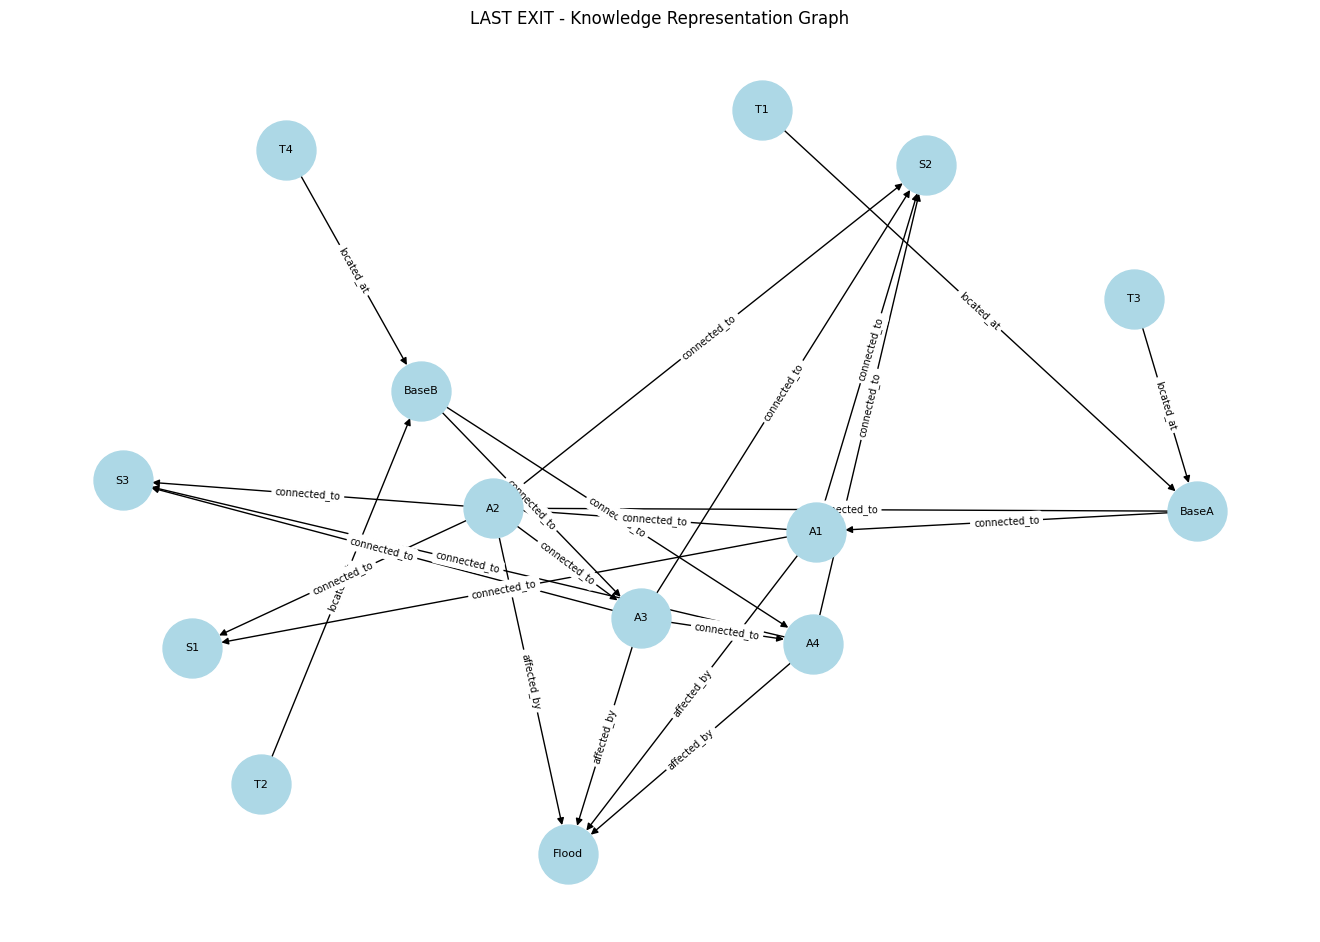

In [ ]:
#Visualize the knowledge graph
plt.figure(figsize=(13, 9))

pos = nx.spring_layout(
    knowledge_graph,
    seed=42,
    k=1.5
)

nx.draw(
    knowledge_graph,
    pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    font_size=8,
    arrows=True
)

edge_labels = nx.get_edge_attributes(
    knowledge_graph,
    "relation"
)

nx.draw_networkx_edge_labels(
    knowledge_graph,
    pos,
    edge_labels=edge_labels,
    font_size=7
)

plt.title("LAST EXIT - Knowledge Representation Graph")
plt.show()

#Exercise 2 – Rule-Based Reasoning
Objective: Create IF–THEN rules using forward or backward chaining to identify evacuation priorities and suggest rescue actions.

In [ ]:
#Implement IF–THEN rules
def forward_chaining(area_data):

    derived_facts = []

    for area, details in area_data.items():

        flood = details["flood"]
        vulnerable = details["vulnerable"]
        population = details["population"]

        # Rule 1: Determine flood risk

        if flood >= 2.0:
            risk_level = "HIGH"

        elif flood >= 1.0:
            risk_level = "MEDIUM"

        else:
            risk_level = "LOW"

        derived_facts.append(
            (area, "has_risk", risk_level)
        )

        # Rule 2: Determine evacuation priority

        if risk_level == "HIGH" or (
            population > 0 and vulnerable / population >= 0.30
        ):

            priority = "HIGH"

        elif risk_level == "MEDIUM":
            priority = "MEDIUM"

        else:
            priority = "LOW"

        derived_facts.append(
            (area, "has_priority", priority)
        )

        # Rule 3: Suggest rescue action

        if priority == "HIGH":
            action = "Immediate evacuation"

        elif priority == "MEDIUM":
            action = "Prepare rescue team"

        else:
            action = "Monitor the area"

        derived_facts.append(
            (area, "requires_action", action)
        )

    return derived_facts


rule_results = forward_chaining(areas)

print("FORWARD CHAINING RESULTS\n")

for fact in rule_results:
    print(fact)

FORWARD CHAINING RESULTS

('A1', 'has_risk', 'HIGH')
('A1', 'has_priority', 'HIGH')
('A1', 'requires_action', 'Immediate evacuation')
('A2', 'has_risk', 'MEDIUM')
('A2', 'has_priority', 'MEDIUM')
('A2', 'requires_action', 'Prepare rescue team')
('A3', 'has_risk', 'LOW')
('A3', 'has_priority', 'LOW')
('A3', 'requires_action', 'Monitor the area')
('A4', 'has_risk', 'HIGH')
('A4', 'has_priority', 'HIGH')
('A4', 'requires_action', 'Immediate evacuation')


In [ ]:
#Display evacuation priorities
priority_data = []

for area, relation, value in rule_results:

    if relation == "has_risk":
        risk = value

    elif relation == "has_priority":
        priority = value

    elif relation == "requires_action":

        priority_data.append({
            "Area": area,
            "Risk": risk,
            "Priority": priority,
            "Action": value
        })

priority_df = pd.DataFrame(priority_data)

display(priority_df)

,Area,Risk,Priority,Action
0,A1,HIGH,HIGH,Immediate evacuation
1,A2,MEDIUM,MEDIUM,Prepare rescue team
2,A3,LOW,LOW,Monitor the area
3,A4,HIGH,HIGH,Immediate evacuation


#Exercise 3 – Handling Uncertainty Using Fuzzy Logic
Objective: Use fuzzy logic or probabilistic reasoning to make decisions when flood levels, road conditions or emergency reports are uncertain.

In [ ]:
#Define fuzzy membership functions
def triangular(x, a, b, c):

    if x <= a or x >= c:
        return 0.0

    elif x == b:
        return 1.0

    elif x < b:
        return (x - a) / (b - a)

    else:
        return (c - x) / (c - b)


def left_shoulder(x, a, b):

    if x <= a:
        return 1.0

    elif x >= b:
        return 0.0

    return (b - x) / (b - a)


def right_shoulder(x, a, b):

    if x <= a:
        return 0.0

    elif x >= b:
        return 1.0

    return (x - a) / (b - a)


def fuzzy_risk(flood, road_safety, confidence):

    # Flood membership

    flood_low = left_shoulder(flood, 0, 1.2)

    flood_medium = triangular(
        flood, 0.5, 1.5, 2.5
    )

    flood_high = right_shoulder(
        flood, 1.5, 3.0
    )

    # Road safety membership

    road_poor = left_shoulder(
        road_safety, 0.2, 0.7
    )

    road_good = right_shoulder(
        road_safety, 0.3, 0.9
    )

    # Report confidence membership

    confidence_low = left_shoulder(
        confidence, 0.3, 0.7
    )

    confidence_high = right_shoulder(
        confidence, 0.3, 0.8
    )

    # Fuzzy rules

    high = max(
        flood_high,
        road_poor,
        min(flood_medium, confidence_high)
    )

    medium = max(
        flood_medium,
        min(flood_high, confidence_low)
    )

    low = min(
        flood_low,
        road_good
    )

    # Weighted average defuzzification

    numerator = (
        low * 20 +
        medium * 55 +
        high * 85
    )

    denominator = low + medium + high

    if denominator == 0:
        return 50

    return numerator / denominator

In [ ]:
#Calculate fuzzy risk for all areas
fuzzy_results = []

for area, details in areas.items():

    score = fuzzy_risk(
        details["flood"],
        details["road_safety"],
        details["confidence"]
    )

    if score >= 70:
        category = "HIGH"

    elif score >= 40:
        category = "MEDIUM"

    else:
        category = "LOW"

    fuzzy_results.append({
        "Area": area,
        "Flood Level": details["flood"],
        "Road Safety": details["road_safety"],
        "Report Confidence": details["confidence"],
        "Risk Score": round(score, 2),
        "Risk Category": category
    })

fuzzy_df = pd.DataFrame(fuzzy_results)

display(fuzzy_df)

,Area,Flood Level,Road Safety,Report Confidence,Risk Score,Risk Category
0,A1,2.4,0.35,0.90,81.25,HIGH
1,A2,1.6,0.55,0.65,68.12,MEDIUM
2,A3,0.8,0.80,0.80,52.14,MEDIUM
3,A4,2.0,0.40,0.55,71.36,HIGH


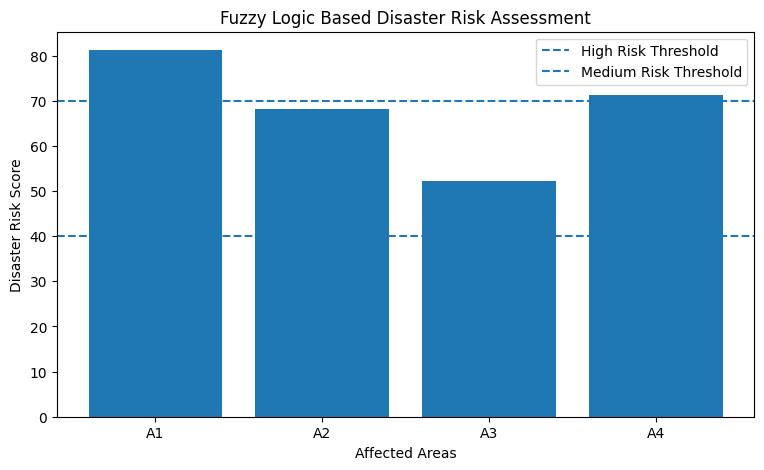

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    fuzzy_df["Area"],
    fuzzy_df["Risk Score"]
)

plt.axhline(
    70,
    linestyle="--",
    label="High Risk Threshold"
)

plt.axhline(
    40,
    linestyle="--",
    label="Medium Risk Threshold"
)

plt.xlabel("Affected Areas")
plt.ylabel("Disaster Risk Score")
plt.title("Fuzzy Logic Based Disaster Risk Assessment")

plt.legend()
plt.show()

#Exercise 4 – Resource Allocation
Objective: Assign rescue teams and shelters while considering available resources, shelter capacity and road conditions.

In [ ]:
#Implement shortest path calculation
def get_working_graph(graph):

    working_graph = graph.copy()

    blocked_edges = [
        (u, v)
        for u, v, data in working_graph.edges(data=True)
        if data.get("blocked", False)
    ]

    working_graph.remove_edges_from(blocked_edges)

    return working_graph


def find_route(graph, source, destination):

    try:

        route = nx.shortest_path(
            graph,
            source,
            destination,
            weight="distance"
        )

        distance = nx.shortest_path_length(
            graph,
            source,
            destination,
            weight="distance"
        )

        return route, distance

    except nx.NetworkXNoPath:

        return None, float("inf")

In [ ]:
#Implement Contract Net Protocol (CNP)
def contract_net_allocation(
    graph,
    area_data,
    team_data,
    shelter_data,
    risk_data
):

    working_graph = get_working_graph(graph)

    # Maintain remaining resources

    remaining_capacity = {
        s: details["capacity"]
        for s, details in shelter_data.items()
    }

    available_shelters = {
        s: details["available"]
        for s, details in shelter_data.items()
    }

    assigned_teams = set()

    # Get priorities from rule-based reasoning

    priority_map = {}

    for _, row in priority_df.iterrows():
        priority_map[row["Area"]] = row["Priority"]

    priority_order = {
        "HIGH": 3,
        "MEDIUM": 2,
        "LOW": 1
    }

    # Sort areas by evacuation priority

    ordered_areas = sorted(
        area_data.keys(),
        key=lambda a: priority_order[
            priority_map[a]
        ],
        reverse=True
    )

    assignments = []
    all_bids = []

    # Coordinator announces tasks

    for area in ordered_areas:

        demand = area_data[area]["population"]

        priority = priority_map[area]

        best_bid = float("inf")
        best_assignment = None

        # Rescue teams submit bids

        for team, details in team_data.items():

            if team in assigned_teams:
                continue

            if details["capacity"] < demand:
                continue

            team_location = details["location"]

            team_route, distance_to_area = find_route(
                working_graph,
                team_location,
                area
            )

            if team_route is None:
                continue

            # Find feasible shelter

            for shelter in shelter_data:

                if not available_shelters[shelter]:
                    continue

                if remaining_capacity[shelter] < demand:
                    continue

                shelter_route, distance_to_shelter = find_route(
                    working_graph,
                    area,
                    shelter
                )

                if shelter_route is None:
                    continue

                total_distance = (
                    distance_to_area +
                    distance_to_shelter
                )

                travel_time = (
                    total_distance /
                    details["speed"]
                )

                # Lower bid = better candidate

                bid = travel_time

                all_bids.append({
                    "Area": area,
                    "Team": team,
                    "Shelter": shelter,
                    "Bid": round(bid, 2)
                })

                if bid < best_bid:

                    best_bid = bid

                    best_assignment = {
                        "Area": area,
                        "Team": team,
                        "Shelter": shelter,
                        "Population": demand,
                        "Priority": priority,
                        "Distance": total_distance,
                        "Time": travel_time,
                        "Route": (
                            team_route +
                            shelter_route[1:]
                        )
                    }

        # Award the contract

        if best_assignment is not None:

            assignments.append(best_assignment)

            assigned_teams.add(
                best_assignment["Team"]
            )

            remaining_capacity[
                best_assignment["Shelter"]
            ] -= demand

    return assignments, all_bids, remaining_capacity

In [ ]:
#Execute the initial resource allocation
initial_assignments, initial_bids, initial_capacity = (
    contract_net_allocation(
        G,
        areas,
        rescue_teams,
        shelters,
        fuzzy_df
    )
)

print("CONTRACT NET PROTOCOL - INITIAL ALLOCATION\n")

for assignment in initial_assignments:

    print("--------------------------------")

    print("Area:", assignment["Area"])
    print("Rescue Team:", assignment["Team"])
    print("Assigned Shelter:", assignment["Shelter"])
    print("Priority:", assignment["Priority"])
    print("People:", assignment["Population"])
    print("Travel Distance:", assignment["Distance"])
    print("Estimated Time:", round(assignment["Time"], 2))
    print("Route:", " -> ".join(assignment["Route"]))

print("\nBIDDING INFORMATION")

bid_df = pd.DataFrame(initial_bids)

display(bid_df)

CONTRACT NET PROTOCOL - INITIAL ALLOCATION

--------------------------------
Area: A1
Rescue Team: T3
Assigned Shelter: S1
Priority: HIGH
People: 120
Travel Distance: 4
Estimated Time: 3.33
Route: BaseA -> A1 -> S1
--------------------------------
Area: A4
Rescue Team: T4
Assigned Shelter: S3
Priority: HIGH
People: 110
Travel Distance: 4.0
Estimated Time: 4.44
Route: BaseB -> A4 -> S3
--------------------------------
Area: A2
Rescue Team: T1
Assigned Shelter: S2
Priority: MEDIUM
People: 90
Travel Distance: 5
Estimated Time: 5.0
Route: BaseA -> A2 -> S2
--------------------------------
Area: A3
Rescue Team: T2
Assigned Shelter: S3
Priority: LOW
People: 70
Travel Distance: 4.5
Estimated Time: 4.09
Route: BaseB -> A3 -> S3

BIDDING INFORMATION


,Area,Team,Shelter,Bid
0,A1,T1,S1,4.00
1,A1,T1,S2,6.00
2,A1,T1,S3,8.00
3,A1,T3,S1,3.33
4,A1,T3,S2,5.00
5,A1,T3,S3,6.67
6,A1,T4,S1,10.00
7,A1,T4,S2,12.22
8,A1,T4,S3,14.44
9,A4,T1,S2,9.00


In [ ]:
#Display shelter utilization
shelter_usage = []

for shelter, details in shelters.items():

    used = (
        details["capacity"] -
        initial_capacity[shelter]
    )

    shelter_usage.append({
        "Shelter": shelter,
        "Total Capacity": details["capacity"],
        "Occupied": used,
        "Available": initial_capacity[shelter]
    })

shelter_df = pd.DataFrame(shelter_usage)

display(shelter_df)

,Shelter,Total Capacity,Occupied,Available
0,S1,150,120,30
1,S2,120,90,30
2,S3,180,180,0


#Exercise 5 – Multi-Agent Coordination
Objective: Use PGP or CNP to coordinate rescue teams, assign tasks and resolve conflicts when multiple teams need the same resources.

In [ ]:
#Define Rescue Team Agent class
class RescueAgent:

    def __init__(self, agent_id, location, capacity, speed):
        self.agent_id = agent_id
        self.location = location
        self.capacity = capacity
        self.speed = speed
        self.available = True
        self.assigned_area = None

    def submit_bid(self, distance, population):
        if not self.available:
            return None

        if population > self.capacity:
            return None

        return distance / self.speed

    def accept_task(self, area):
        self.available = False
        self.assigned_area = area
        print(
            f"{self.agent_id} accepted task for {area}"
        )

    def complete_task(self):
        self.available = True
        self.assigned_area = None
        print(
            f"{self.agent_id} completed rescue operation"
        )

In [ ]:
#Create rescue agents
agents = {}

for team, details in rescue_teams.items():

    agents[team] = RescueAgent(
        agent_id=team,
        location=details["location"],
        capacity=details["capacity"],
        speed=details["speed"]
    )

print("RESCUE AGENTS CREATED\n")

for agent in agents.values():

    print(
        agent.agent_id,
        "| Location:", agent.location,
        "| Capacity:", agent.capacity,
        "| Speed:", agent.speed,
        "| Available:", agent.available
    )

RESCUE AGENTS CREATED

T1 | Location: BaseA | Capacity: 140 | Speed: 1.0 | Available: True
T2 | Location: BaseB | Capacity: 100 | Speed: 1.1 | Available: True
T3 | Location: BaseA | Capacity: 120 | Speed: 1.2 | Available: True
T4 | Location: BaseB | Capacity: 120 | Speed: 0.9 | Available: True


In [ ]:
#Demonstrate agent coordination
print("MULTI-AGENT COORDINATION\n")

for assignment in initial_assignments:
    team = assignment["Team"]
    area = assignment["Area"]
    agents[team].accept_task(area)

print("\nCURRENT AGENT STATUS\n")

for agent in agents.values():

    print(
        agent.agent_id,
        "| Available:", agent.available,
        "| Assigned Area:", agent.assigned_area
    )

MULTI-AGENT COORDINATION

T3 accepted task for A1
T4 accepted task for A4
T1 accepted task for A2
T2 accepted task for A3

CURRENT AGENT STATUS

T1 | Available: False | Assigned Area: A2
T2 | Available: False | Assigned Area: A3
T3 | Available: False | Assigned Area: A1
T4 | Available: False | Assigned Area: A4


In [ ]:
#Simulate completion of rescue tasks
print("RESCUE TASK EXECUTION\n")

for assignment in initial_assignments:

    team = assignment["Team"]

    agents[team].complete_task()

print("\nFINAL AGENT STATUS\n")

for agent in agents.values():

    print(
        agent.agent_id,
        "| Available:", agent.available,
        "| Assigned Area:", agent.assigned_area
    )

RESCUE TASK EXECUTION

T3 completed rescue operation
T4 completed rescue operation
T1 completed rescue operation
T2 completed rescue operation

FINAL AGENT STATUS

T1 | Available: True | Assigned Area: None
T2 | Available: True | Assigned Area: None
T3 | Available: True | Assigned Area: None
T4 | Available: True | Assigned Area: None


#Exercise 6 – Simulation and Evaluation
Objective: Test the system under different disaster scenarios, introduce unexpected events and evaluate the system's response.

In [ ]:
#Simulate the normal disaster scenario
def calculate_metrics(assignments, total_population, shelter_data):

    evacuated = sum(
        a["Population"] for a in assignments
    )

    total_time = max(
        [a["Time"] for a in assignments],
        default=0
    )

    teams_used = len(set(
        a["Team"] for a in assignments
    ))

    shelters_used = len(set(
        a["Shelter"] for a in assignments
    ))

    return {
        "Total Population": total_population,
        "People Evacuated": evacuated,
        "People Remaining": total_population - evacuated,
        "Evacuation Time": round(total_time, 2),
        "Teams Used": teams_used,
        "Shelters Used": shelters_used,
        "Evacuation Percentage": round(
            evacuated / total_population * 100, 2
        )
    }


total_population = sum(
    details["population"]
    for details in areas.values()
)

normal_metrics = calculate_metrics(
    initial_assignments,
    total_population,
    shelters
)

print("NORMAL SCENARIO RESULTS\n")

for key, value in normal_metrics.items():

    print(key, ":", value)

NORMAL SCENARIO RESULTS

Total Population : 390
People Evacuated : 390
People Remaining : 0
Evacuation Time : 5.0
Teams Used : 4
Shelters Used : 3
Evacuation Percentage : 100.0


In [ ]:
#Introduce unexpected events

# Create copies of the original environment

disaster_graph = deepcopy(G)
disaster_shelters = deepcopy(shelters)

# Unexpected Event 1: Road blockage
disaster_graph["A2"]["S1"]["blocked"] = True
print("EVENT 1: Road A2 -> S1 is BLOCKED")

# Unexpected Event 2: Shelter unavailable
disaster_shelters["S2"]["available"] = False
print("EVENT 2: Shelter S2 is UNAVAILABLE")
print("\nUpdated Road Conditions:")

for u, v, data in disaster_graph.edges(data=True):

    if data["blocked"]:

        print(u, "<->", v, ": BLOCKED")

EVENT 1: Road A2 -> S1 is BLOCKED
EVENT 2: Shelter S2 is UNAVAILABLE

Updated Road Conditions:
A2 <-> S1 : BLOCKED


In [ ]:
#Reallocate resources after the disaster
updated_assignments, updated_bids, updated_capacity = (
    contract_net_allocation(
        disaster_graph,
        areas,
        rescue_teams,
        disaster_shelters,
        fuzzy_df
    )
)

print("UPDATED EVACUATION PLAN\n")

for assignment in updated_assignments:

    print("--------------------------------")

    print("Area:", assignment["Area"])
    print("Rescue Team:", assignment["Team"])
    print("Shelter:", assignment["Shelter"])
    print("Population:", assignment["Population"])
    print("Estimated Time:", round(assignment["Time"], 2))
    print("New Route:", " -> ".join(assignment["Route"]))

UPDATED EVACUATION PLAN

--------------------------------
Area: A1
Rescue Team: T3
Shelter: S1
Population: 120
Estimated Time: 3.33
New Route: BaseA -> A1 -> S1
--------------------------------
Area: A4
Rescue Team: T4
Shelter: S3
Population: 110
Estimated Time: 4.44
New Route: BaseB -> A4 -> S3
--------------------------------
Area: A3
Rescue Team: T2
Shelter: S3
Population: 70
Estimated Time: 4.09
New Route: BaseB -> A3 -> S3


In [ ]:
#Compare normal and unexpected-event scenarios
updated_metrics = calculate_metrics(
    updated_assignments,
    total_population,
    disaster_shelters
)

comparison_df = pd.DataFrame(
    [
        normal_metrics,
        updated_metrics
    ],
    index=[
        "Normal Scenario",
        "Unexpected Event"
    ]
)

print("SCENARIO COMPARISON\n")

display(comparison_df.T)

SCENARIO COMPARISON



,Normal Scenario,Unexpected Event
Total Population,390.0,390.00
People Evacuated,390.0,300.00
People Remaining,0.0,90.00
Evacuation Time,5.0,4.44
Teams Used,4.0,3.00
Shelters Used,3.0,2.00
Evacuation Percentage,100.0,76.92


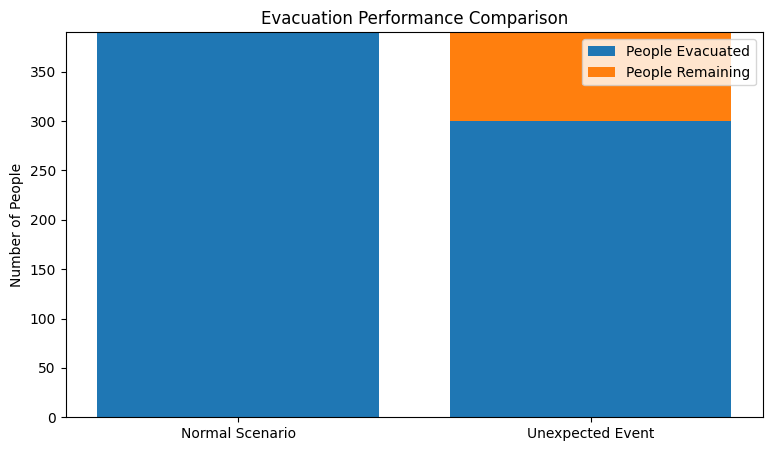

In [ ]:
scenario_names = [
    "Normal Scenario",
    "Unexpected Event"
]

evacuated_people = [
    normal_metrics["People Evacuated"],
    updated_metrics["People Evacuated"]
]

remaining_people = [
    normal_metrics["People Remaining"],
    updated_metrics["People Remaining"]
]

x = np.arange(len(scenario_names))

plt.figure(figsize=(9, 5))

plt.bar(
    x,
    evacuated_people,
    label="People Evacuated"
)

plt.bar(
    x,
    remaining_people,
    bottom=evacuated_people,
    label="People Remaining"
)

plt.xticks(x, scenario_names)

plt.ylabel("Number of People")

plt.title("Evacuation Performance Comparison")

plt.legend()

plt.show()

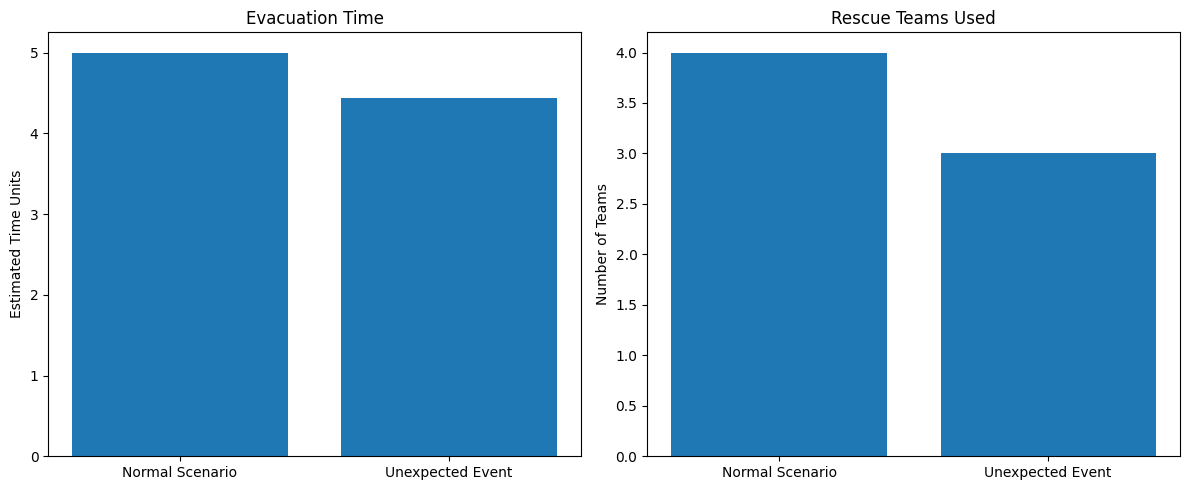

In [ ]:
#Compare evacuation time and resource usage
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Evacuation time

axes[0].bar(
    scenario_names,
    [
        normal_metrics["Evacuation Time"],
        updated_metrics["Evacuation Time"]
    ]
)

axes[0].set_title("Evacuation Time")
axes[0].set_ylabel("Estimated Time Units")

# Rescue team utilization

axes[1].bar(
    scenario_names,
    [
        normal_metrics["Teams Used"],
        updated_metrics["Teams Used"]
    ]
)

axes[1].set_title("Rescue Teams Used")
axes[1].set_ylabel("Number of Teams")

plt.tight_layout()

plt.show()

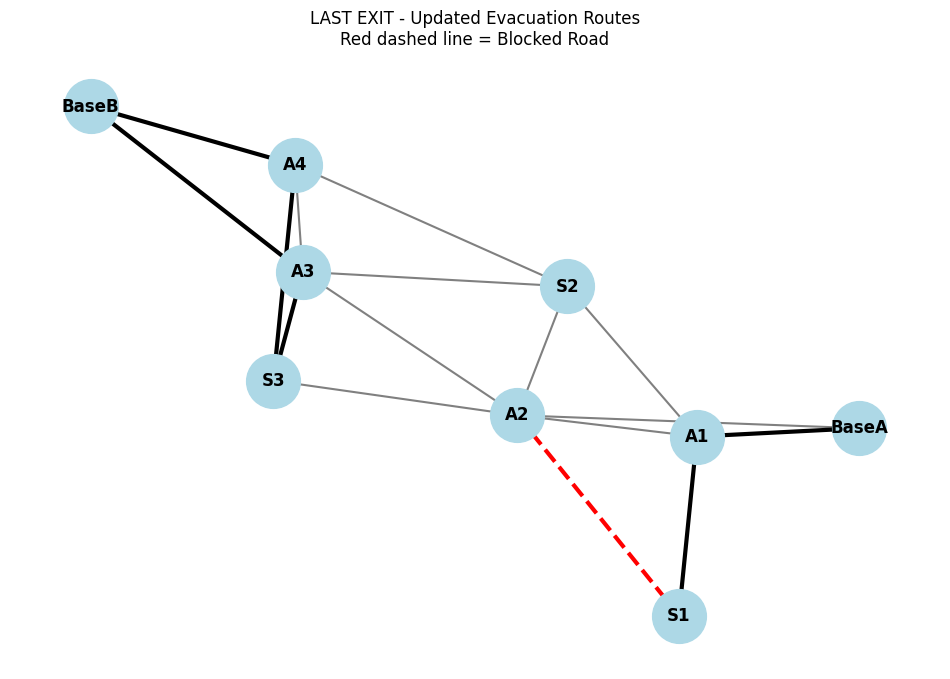

In [ ]:
#Visualize the updated evacuation network
def plot_evacuation_routes(graph, assignments):

    pos = nx.spring_layout(graph, seed=42)

    plt.figure(figsize=(12, 8))

    nx.draw_networkx_nodes(
        graph,
        pos,
        node_color="lightblue",
        node_size=1500
    )

    nx.draw_networkx_labels(
        graph,
        pos,
        font_weight="bold"
    )

    # Available roads

    available_edges = [
        (u, v)
        for u, v, d in graph.edges(data=True)
        if not d["blocked"]
    ]

    # Blocked roads

    blocked_edges = [
        (u, v)
        for u, v, d in graph.edges(data=True)
        if d["blocked"]
    ]

    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=available_edges,
        edge_color="gray",
        width=1.5
    )

    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=blocked_edges,
        edge_color="red",
        width=3,
        style="dashed"
    )

    # Draw evacuation routes

    for assignment in assignments:

        route = assignment["Route"]

        route_edges = list(
            zip(route[:-1], route[1:])
        )

        nx.draw_networkx_edges(
            graph,
            pos,
            edgelist=route_edges,
            width=3
        )

    plt.title(
        "LAST EXIT - Updated Evacuation Routes\n"
        "Red dashed line = Blocked Road"
    )

    plt.axis("off")

    plt.show()


plot_evacuation_routes(
    disaster_graph,
    updated_assignments
)

In [ ]:
print("=" * 55)
print("       LAST EXIT - FINAL EVALUATION REPORT")
print("=" * 55)

print("\n1. KNOWLEDGE REPRESENTATION")
print("Knowledge graph created using NetworkX.")
print("Entities and relationships represented successfully.")

print("\n2. RULE-BASED REASONING")
print("Forward chaining implemented.")
print("Evacuation priorities determined using IF-THEN rules.")

print("\n3. HANDLING UNCERTAINTY")
print("Fuzzy logic implemented.")
print("Disaster risk calculated using flood, road and report data.")

print("\n4. RESOURCE ALLOCATION")
print("Rescue teams and shelters allocated.")
print("Capacity and road availability considered.")

print("\n5. MULTI-AGENT COORDINATION")
print("Contract Net Protocol implemented.")
print("Agents submit bids and receive evacuation tasks.")

print("\n6. SIMULATION AND EVALUATION")

print("\nNormal Scenario:")
for key, value in normal_metrics.items():
    print(key, ":", value)

print("\nUnexpected Event Scenario:")
for key, value in updated_metrics.items():
    print(key, ":", value)

print("\n" + "=" * 55)
print("       EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 55)

       LAST EXIT - FINAL EVALUATION REPORT

1. KNOWLEDGE REPRESENTATION
Knowledge graph created using NetworkX.
Entities and relationships represented successfully.

2. RULE-BASED REASONING
Forward chaining implemented.
Evacuation priorities determined using IF-THEN rules.

3. HANDLING UNCERTAINTY
Fuzzy logic implemented.
Disaster risk calculated using flood, road and report data.

4. RESOURCE ALLOCATION
Rescue teams and shelters allocated.
Capacity and road availability considered.

5. MULTI-AGENT COORDINATION
Contract Net Protocol implemented.
Agents submit bids and receive evacuation tasks.

6. SIMULATION AND EVALUATION

Normal Scenario:
Total Population : 390
People Evacuated : 390
People Remaining : 0
Evacuation Time : 5.0
Teams Used : 4
Shelters Used : 3
Evacuation Percentage : 100.0

Unexpected Event Scenario:
Total Population : 390
People Evacuated : 300
People Remaining : 90
Evacuation Time : 4.44
Teams Used : 3
Shelters Used : 2
Evacuation Percentage : 76.92

       EXPERIMEN